# Notebook 06 — full-data ConvNeXt V2 at 192px

Train the ConvNeXt V2 configuration that contributed to our **0.9806 public-score ensemble**, now using all **63,645 cleaned labelled images**. The previous V2 run trained on 54,098 images and selected epoch 7. This new run uses a fixed **seven-epoch** budget, batch size 64, training seed 42, and the same model, augmentation, normalization and optimizer settings.

**Inputs:** attach the original Competition dataset and either the supplied small `08_training_metadata_cache.zip` as a private dataset or the saved outputs of Notebook 4. One of the existing full-data-pair, confirmation, or controlled-experiment backups also provides the same cached training metadata. Loose metadata files and these ZIPs are supported. The three original `eng707-models` checkpoints are not needed for this training run.

**Settings:** enable a GPU and Internet for the public pretrained weights. No Hugging Face token is required for this public model. Keep the same Kaggle package environment where possible. No packages are installed or upgraded by this notebook.

**Run All applies to this new Notebook 06.** It checks the cached metadata, trains one model and exports clean/TTA test probabilities. It does not rerun Notebook 4, repeat the image audits, overwrite earlier experiment folders, select a submission, or submit to Kaggle. A verified completed checkpoint and verified predictions are reused on a later run of this notebook. An incomplete training run is preserved and stops with an explanation rather than being silently restarted.

Budget roughly **1–2 hours**, based on the previous run; hardware and image I/O can change this substantially. There is no independent validation accuracy for a model trained on all labelled images. More training data is a testable hypothesis, not a promise of a higher score.

Pretrained model reference: [official timm model card](https://huggingface.co/timm/convnextv2_tiny.fcmae_ft_in1k).

In [1]:
import os
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret(
    "kaggle-assignment3"
)

In [2]:
from pathlib import Path
import copy, hashlib, json, math, platform, random, shutil, time, zipfile
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
import timm
from timm.data import resolve_model_data_config
from sklearn.metrics import accuracy_score, log_loss
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

# Set explicit paths only if automatic discovery finds ambiguity or cannot find the cache.
BASE = None
METADATA_PATH = None
RECOVERY_ROOT = None  # Optional directory containing a saved completed Notebook 08 output.
MODEL_NAME = 'convnextv2_tiny.fcmae_ft_in1k'
TRAIN_SEED = 42
NUM_WORKERS = 2
BATCH_SIZE = 64
FULL_DATA = True
FULL_EPOCHS = 7
SPLIT_SEED = None  # No holdout split is used for this full-data run.
split_hash = None
CLASSES = ['CatEye','CatFace','CatMouth','CatNose','DogEye','DogFace','DogMouth','DogNose']
CLASS_TO_IDX = {c:i for i,c in enumerate(CLASSES)}
EXPECTED_LABEL_SHA = '94124e856786379a9c1e9c8c7ba4599a9f27fe8dc6ea4165dc4afc55024d41a3'
EXPECTED_META_SHA = '26e27a97a6be1827aa21dfb99cd7191de8038b42303acf87d9568d46cb25bd50'
EXPECTED_MEAN = [.485,.456,.406]
EXPECTED_STD = [.229,.224,.225]
OUT = Path('/kaggle/working/full_data_convnextv2_192_seed42')
RUN_DIR = OUT/'convnextv2_tiny_192_geometry_full_seed42'
CFG = dict(model=MODEL_NAME,size=192,geometry=True,epochs=7,batch_size=64,
           lr=3e-4,weight_decay=.05,label_smoothing=.1,downscale_p=.3,
           training_images=63645,cached_metadata_sha256=EXPECTED_META_SHA,
           intended_train_seed=TRAIN_SEED)

assert torch.cuda.is_available(), 'Enable a Kaggle GPU before running this new notebook.'
assert MODEL_NAME in timm.list_models(pretrained=True), 'This model is unavailable in the attached timm environment.'
device=torch.device('cuda')
versions=dict(python=platform.python_version(),torch=str(torch.__version__),
              torchvision=str(torchvision.__version__),timm=str(timm.__version__))
print('GPU:',torch.cuda.get_device_name(0),'| versions:',versions)

# Check normalization before spending time on training or downloading weights.
probe=timm.create_model(MODEL_NAME,pretrained=False,num_classes=len(CLASSES))
resolved=resolve_model_data_config(probe)
assert np.allclose(resolved['mean'],EXPECTED_MEAN) and np.allclose(resolved['std'],EXPECTED_STD), (
    'Pretrained normalization differs from the earlier V2 run; review the environment before training.')
del probe
print('Configuration ready: one full-data V2 model, 192px, seven epochs, batch size 64.')


GPU: Tesla T4 | versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'timm': '1.0.29'}
Configuration ready: one full-data V2 model, 192px, seven epochs, batch size 64.


## 1. Reuse the completed data audit

The following cell reads the original label CSV and cached metadata only. It verifies the cached cleaned rows against the exact metadata fingerprint from the completed experiments. It does not reopen every image or recompute image hashes. If no matching cache is attached, it stops and explains which saved output to attach.

In [3]:
def image_folder(base,kind):
    for path in [base/kind/kind,base/kind]:
        if (path/'00001.jpg').is_file(): return path
    raise FileNotFoundError(f'Missing {kind} images under {base}')

def validate_cached_metadata(meta,official_labels):
    required={'image_id','class','width','height','md5'}
    assert required.issubset(meta.columns), 'Cache is missing required audit columns.'
    assert len(meta) in [63645,63660] and meta.image_id.is_unique
    assert not meta[list(required)].isna().any().any()
    assert np.issubdtype(meta.image_id.dtype,np.integer)
    official=official_labels.set_index('image_id')['class']
    assert meta.image_id.isin(official.index).all()
    assert np.array_equal(meta['class'].to_numpy(),official.loc[meta.image_id].to_numpy())
    assert meta.md5.astype(str).str.fullmatch('[0-9a-f]{32}').all()
    assert meta.groupby('md5')['class'].nunique().max()==1
    cleaned=meta.drop_duplicates('md5',keep='first').copy()
    assert len(cleaned)==63645 and cleaned.md5.is_unique
    # Preserve the original label-file row order for seeded data loading.
    ids=official_labels.loc[official_labels.image_id.isin(cleaned.image_id),'image_id']
    cleaned=cleaned.set_index('image_id').loc[ids].reset_index()
    cleaned['image_id']=cleaned.image_id.astype('int64')
    cleaned['width']=cleaned.width.astype('int64')
    cleaned['height']=cleaned.height.astype('int64')
    assert (cleaned[['width','height']]>0).all().all()
    canonical=cleaned[['image_id','class','width','height','md5']].sort_values('image_id').reset_index(drop=True)
    digest=hashlib.sha256(canonical.to_csv(index=False,lineterminator='\n').encode()).hexdigest()
    assert digest==EXPECTED_META_SHA, 'Cached cleaned metadata differs from the completed experiments.'
    cleaned['label']=cleaned['class'].map(CLASS_TO_IDX).astype('int64')
    return cleaned

def cached_metadata_sources():
    if METADATA_PATH is not None:
        path=Path(METADATA_PATH)
        yield str(path),pd.read_csv(path)
        return
    roots=[Path('/kaggle/working'),Path('/kaggle/input')]
    paths=set()
    for root in roots:
        if root.exists():
            paths.update(root.rglob('full_training_metadata.csv'))
            paths.update(root.rglob('train_metadata_*.csv'))
    for path in sorted(paths,key=lambda p:(p.name!='full_training_metadata.csv',str(p))):
        try: yield str(path),pd.read_csv(path)
        except (OSError,ValueError,pd.errors.ParserError): continue
    # Read only a small metadata member, not the large checkpoint files.
    for root in roots:
        if not root.exists(): continue
        zip_paths=set(root.rglob('*backup.zip'))
        zip_paths.update(root.rglob('08_training_metadata_cache.zip'))
        for path in sorted(zip_paths):
            try:
                with zipfile.ZipFile(path) as archive:
                    names=[name for name in archive.namelist()
                           if Path(name).name=='full_training_metadata.csv'
                           or (Path(name).name.startswith('train_metadata_') and name.endswith('.csv'))]
                    for name in sorted(names,key=lambda s:(Path(s).name!='full_training_metadata.csv',s)):
                        with archive.open(name) as member:
                            frame=pd.read_csv(member)
                        yield f'{path}::{name}',frame
            except (OSError,zipfile.BadZipFile,ValueError,pd.errors.ParserError): continue

if BASE is None:
    possibilities=[]
    for path in Path('/kaggle/input').rglob('train_labels.csv'):
        if not (path.parent/'sample_submission.csv').is_file(): continue
        try:
            image_folder(path.parent,'train'); image_folder(path.parent,'test')
        except FileNotFoundError: continue
        possibilities.append(path.parent)
    assert len(possibilities)==1, f'Found {len(possibilities)} competition folders. Set BASE explicitly: {possibilities}'
    BASE=possibilities[0]
else:
    BASE=Path(BASE)
TRAIN_DIR=image_folder(BASE,'train'); TEST_DIR=image_folder(BASE,'test')
labels=pd.read_csv(BASE/'train_labels.csv')
sample=pd.read_csv(BASE/'sample_submission.csv')
assert labels.columns.tolist()==sample.columns.tolist()==['image_id','class']
assert len(labels)==63660 and labels.image_id.is_unique and not labels.isna().any().any()
assert set(labels['class'])==set(CLASSES)
assert len(sample)==29443 and sample.image_id.is_unique and not sample.isna().any().any()
label_sha=hashlib.sha256((BASE/'train_labels.csv').read_bytes()).hexdigest()
assert label_sha==EXPECTED_LABEL_SHA, 'The competition label file differs from the one previously audited.'
cache_errors=[]; df=None; cache_source=None
for origin,frame in cached_metadata_sources():
    try:
        df=validate_cached_metadata(frame,labels)
        cache_source=origin
        break
    except (AssertionError,KeyError,ValueError,TypeError) as error:
        cache_errors.append(f'{origin}: {error}')
assert df is not None, (
    'Attach the saved Notebook 4 output, or a private dataset containing full_data_pair_128_backup.zip, '
    'confirmation_split1337_backup.zip, or controlled_experiments_backup.zip. '
    'The old image audit will not be repeated. Details: '+str(cache_errors[:3]))
train_df=df
val_df=df.iloc[:0].copy()
print('Competition:',BASE)
print('Reused cache:',cache_source)
print('Verified cleaned training images:',len(df),'| test images:',len(sample))
print('No complete image audit was run.')


Competition: /kaggle/input/datasets/khlafalshammari/competition
Reused cache: /kaggle/input/datasets/khlafalshammari/08-training/full_training_metadata.csv
Verified cleaned training images: 63645 | test images: 29443
No complete image audit was run.


## 2. The same training and prediction pipeline

These definitions are copied unchanged from the completed Notebook 4: RGB decoding, geometry augmentation, normalization, training with smoothed cross-entropy, AdamW, AMP and a one-epoch warmup followed by cosine decay. The earlier selected V2 checkpoint was epoch 7 of an eight-epoch schedule; the new full-data model has a seven-epoch schedule. This is a full-data refit, not a claim that every optimizer update reproduces the earlier run.

In [4]:
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed); random.seed(worker_seed)

class RandomDownscale:
    def __init__(self, p=.3): self.p=p
    def __call__(self, img):
        if random.random() < self.p:
            target=random.randint(16,48); short=min(img.size)
            if short > target:
                scale=target/short
                img=img.resize((max(1,round(img.width*scale)), max(1,round(img.height*scale))),
                               Image.Resampling.BILINEAR)
        return img

class AxisPad:
    def __init__(self, p=.5, max_fraction=.15, fixed=None):
        self.p, self.max_fraction, self.fixed = p, max_fraction, fixed
    def __call__(self, img):
        if self.fixed is None:
            if random.random() >= self.p: return img
            fx=random.uniform(0,self.max_fraction)
            fy=random.uniform(0,self.max_fraction)
        else:
            fx,fy=self.fixed
        w,h=img.size
        px,py=round(w*fx),round(h*fy)
        # This runs after square resizing: padding is always smaller than either side.
        return TF.pad(img, [px,py,px,py], padding_mode='reflect')

def transforms_for(cfg, training=False, stress=None):
    s=cfg['size']; ops=[]
    if training: ops.append(RandomDownscale(cfg['downscale_p']))
    ops.append(T.Resize((s,s), interpolation=T.InterpolationMode.BILINEAR, antialias=True))
    if training and cfg['geometry']:
        ops.extend([AxisPad(), T.Resize((s,s), antialias=True)])
    if stress:
        fixed={'wide':(0,.15), 'tall':(.15,0)}[stress]
        ops.extend([AxisPad(fixed=fixed), T.Resize((s,s), antialias=True)])
    if training:
        ops.extend([T.RandomHorizontalFlip(.5),
                    T.RandomAffine(degrees=10, translate=(.05,.05), scale=(.9,1.1)),
                    T.ColorJitter(brightness=.3, contrast=.3, saturation=.2)])
    ops.extend([T.ToTensor(), T.Normalize(cfg['mean'],cfg['std'])])
    return T.Compose(ops)

class Images(Dataset):
    def __init__(self, frame, folder, transform):
        self.frame=frame.reset_index(drop=True); self.folder=folder; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        r=self.frame.iloc[i]; image_id=int(r['image_id'])
        with Image.open(self.folder/f'{image_id:05d}.jpg') as im:
            x=self.transform(im.convert('RGB'))
        y=int(r['label']) if 'label' in self.frame.columns else -1
        return x,y,image_id

def loader_for(frame, folder, cfg, training=False, stress=None):
    return DataLoader(Images(frame,folder,transforms_for(cfg,training,stress)),
                      batch_size=BATCH_SIZE, shuffle=training, drop_last=False,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      persistent_workers=NUM_WORKERS>0, worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(TRAIN_SEED))

@torch.inference_mode()
def predict(model, loader, flip=False):
    model.eval(); probs=[]; labels_out=[]; ids=[]
    for x,y,image_ids in loader:
        x=x.to(device,non_blocking=True)
        with torch.autocast('cuda',dtype=torch.float16):
            logits=model(x)
        p=logits.float().softmax(1)
        if flip:
            with torch.autocast('cuda',dtype=torch.float16):
                flipped=model(torch.flip(x,[3]))
            p=(p+flipped.float().softmax(1))/2
        probs.append(p.cpu().numpy()); labels_out.append(y.numpy()); ids.append(image_ids.numpy())
    return np.concatenate(probs),np.concatenate(labels_out),np.concatenate(ids)

def metrics(y,p):
    assert p.shape == (len(y),len(CLASSES))
    assert np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
    return {'accuracy':float(accuracy_score(y,p.argmax(1))),
            'nll':float(log_loss(y,p,labels=np.arange(len(CLASSES)))),
            'errors':int((p.argmax(1)!=y).sum())}

def fit(cfg, run_dir):
    seed_all(TRAIN_SEED)
    model=timm.create_model(cfg['model'],pretrained=True,num_classes=len(CLASSES)).to(device)
    data_cfg=resolve_model_data_config(model)
    cfg=copy.deepcopy(cfg)
    cfg['mean']=list(data_cfg['mean']); cfg['std']=list(data_cfg['std'])
    cfg.update(split_seed=SPLIT_SEED, train_seed=TRAIN_SEED, full_data=FULL_DATA,
               classes=CLASSES, label_sha256=label_sha, split_hash=None if FULL_DATA else split_hash,
               versions=versions)
    train_frame=df if FULL_DATA else train_df
    train_loader=loader_for(train_frame,TRAIN_DIR,cfg,training=True)
    val_loader=None if FULL_DATA else loader_for(val_df,TRAIN_DIR,cfg)
    epochs=FULL_EPOCHS if FULL_DATA else cfg['epochs']
    cfg['actual_epochs']=epochs
    (run_dir/'config.json').write_text(json.dumps(cfg,indent=2))
    opt=torch.optim.AdamW(model.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    total_steps=epochs*len(train_loader); warmup_steps=len(train_loader)
    def schedule(step):
        if step<warmup_steps:return (step+1)/warmup_steps
        progress=(step-warmup_steps)/max(1,total_steps-warmup_steps)
        return .5*(1+math.cos(math.pi*min(progress,1)))
    scheduler=torch.optim.lr_scheduler.LambdaLR(opt,schedule)
    scaler=torch.amp.GradScaler('cuda')
    criterion=nn.CrossEntropyLoss(label_smoothing=cfg['label_smoothing'])
    history=[]; best=(-1.,-float('inf')); best_path=run_dir/'best.pth'
    skipped=0
    for epoch in range(1,epochs+1):
        start=time.time(); model.train(); loss_sum=0.; correct=0; n=0
        for x,y,_ in tqdm(train_loader,desc=f'{run_dir.name} epoch {epoch}/{epochs}',leave=False):
            x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(x);loss=criterion(logits,y)
            scale_before=scaler.get_scale()
            scaler.scale(loss).backward();scaler.step(opt);scaler.update()
            if scaler.get_scale()>=scale_before:scheduler.step()
            else:skipped+=1
            loss_sum+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item();n+=len(y)
        row=dict(epoch=epoch,train_loss=loss_sum/n,train_acc=correct/n,
                 skipped_updates=skipped,seconds=round(time.time()-start,1))
        if not FULL_DATA:
            p,y,ids=predict(model,val_loader)
            assert np.array_equal(ids,val_df.image_id.to_numpy())
            m=metrics(y,p);row.update(val_acc=m['accuracy'],val_nll=m['nll'],val_errors=m['errors'])
            rank=(m['accuracy'],-m['nll'])
            save=rank>best
            if save:best=rank
        else:
            save=True # Save the latest epoch; there is deliberately no validation score.
        if save:
            torch.save({'model':model.state_dict(),'config':cfg,'epoch':epoch,
                        'validation':None if FULL_DATA else m},best_path)
        history.append(row);pd.DataFrame(history).to_csv(run_dir/'history.csv',index=False)
        print(row)
    del train_loader,val_loader
    checkpoint=torch.load(best_path,map_location='cpu',weights_only=False)
    model.load_state_dict(checkpoint['model'])
    print('Loaded checkpoint epoch',checkpoint['epoch'])
    return model,cfg,pd.DataFrame(history)

def save_probabilities(path, probs, ids, y=None):
    payload=dict(probs=probs,image_id=ids,classes=np.array(CLASSES),
                 split_hash=np.array('full_data' if FULL_DATA else split_hash))
    if y is not None: payload['labels']=y
    np.savez_compressed(path,**payload)


## 3. Train one full-data model, or reuse its verified completed checkpoint

The checkpoint named `best.pth` stores the last fixed epoch for this full-data model. Its validation field is `None`. Training accuracy is not a holdout score. A previous partial training run is not automatically continued because its optimizer state was not saved by the original training function.

START: 63,645 training images, 7 epochs, 192px, batch size 64.
This full-data run has no holdout validation score.


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

convnextv2_tiny_192_geometry_full_seed42 epoch 1/7:   0%|          | 0/995 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.6782892345529911, 'train_acc': 0.9059941865032602, 'skipped_updates': 3, 'seconds': 2206.0}


...

{'epoch': 5, 'train_loss': 0.4798041841607128, 'train_acc': 0.9940608060334669, 'skipped_updates': 3, 'seconds': 503.9}


convnextv2_tiny_192_geometry_full_seed42 epoch 6/7:   0%|          | 0/995 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.4728279910357115, 'train_acc': 0.9975174797706026, 'skipped_updates': 3, 'seconds': 504.4}


convnextv2_tiny_192_geometry_full_seed42 epoch 7/7:   0%|          | 0/995 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.4709325415517391, 'train_acc': 0.9982088145180297, 'skipped_updates': 3, 'seconds': 504.1}
Loaded checkpoint epoch 7


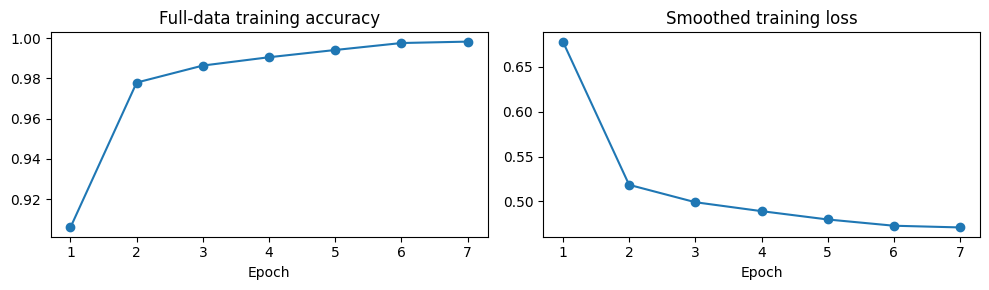

In [5]:
plan=dict(model=MODEL_NAME,input_size=192,geometry=True,epochs=FULL_EPOCHS,
          batch_size=BATCH_SIZE,training_seed=TRAIN_SEED,training_images=len(df),
          label_sha256=label_sha,cached_metadata_sha256=EXPECTED_META_SHA,
          initialization='Same public pretrained weights; not the earlier fine-tuned checkpoint.',
          epoch_budget_reason='The earlier held-out V2 run selected epoch 7.',
          validation_metrics_available=False,benchmark_public_score_at_creation=.9806,
          cache_source=cache_source,model_reference='https://huggingface.co/timm/convnextv2_tiny.fcmae_ft_in1k')

# Recover a completed saved Notebook 08 output when working-file persistence was lost.
if not (RUN_DIR/'best.pth').exists():
    if RECOVERY_ROOT is not None:
        recovery_sources=[Path(RECOVERY_ROOT)]
    else:
        recovery_sources=sorted({p.parent for p in Path('/kaggle/input').rglob('training_plan.json')
                                 if p.parent.name==OUT.name
                                 and (p.parent/RUN_DIR.name/'best.pth').is_file()})
    assert len(recovery_sources)<=1, 'Several saved full-data V2 runs are attached. Set RECOVERY_ROOT explicitly.'
    if recovery_sources:
        source_root=recovery_sources[0]
        saved_plan=json.loads((source_root/'training_plan.json').read_text())
        for key in ['model','input_size','geometry','epochs','batch_size','training_seed',
                    'training_images','label_sha256','cached_metadata_sha256']:
            assert saved_plan[key]==plan[key], f'Recovery source differs for {key}.'
        saved_history=pd.read_csv(source_root/RUN_DIR.name/'history.csv')
        assert saved_history.epoch.tolist()==list(range(1,FULL_EPOCHS+1)), 'Recovery source is incomplete.'
        assert not OUT.exists(), (
            'A saved completed run is available, but a working folder already exists. '
            'Preserve both and review them before copying or training.')
        shutil.copytree(source_root,OUT)
        print('RESTORED saved full-data V2 output:',source_root,flush=True)
OUT.mkdir(parents=True,exist_ok=True)
RUN_DIR.mkdir(exist_ok=True)
plan_path=OUT/'training_plan.json'
if plan_path.exists():
    old_plan=json.loads(plan_path.read_text())
    for key in ['model','input_size','geometry','epochs','batch_size','training_seed',
                'training_images','label_sha256','cached_metadata_sha256']:
        assert old_plan[key]==plan[key], f'Existing run settings differ for {key}; preserve this folder.'
else:
    plan_path.write_text(json.dumps(plan,indent=2))
df.to_csv(OUT/'full_training_metadata.csv',index=False)
(OUT/'versions_current_session.json').write_text(json.dumps(versions,indent=2))
checkpoint_path=RUN_DIR/'best.pth'
if checkpoint_path.exists():
    checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=False)
    cfg=checkpoint['config']
    assert checkpoint['epoch']==FULL_EPOCHS and cfg['actual_epochs']==FULL_EPOCHS, (
        'An incomplete checkpoint is preserved here. It cannot be silently resumed with the original fit function; '
        'review the failed run before choosing another output folder.')
    assert cfg['full_data'] is True and checkpoint['validation'] is None
    assert cfg['model']==MODEL_NAME and cfg['size']==192 and cfg['geometry'] is True
    assert cfg['batch_size']==BATCH_SIZE and cfg['train_seed']==TRAIN_SEED
    assert cfg['training_images']==63645 and cfg['classes']==CLASSES
    assert cfg['cached_metadata_sha256']==EXPECTED_META_SHA and cfg['label_sha256']==label_sha
    for key in ['lr','weight_decay','label_smoothing','downscale_p']:
        assert cfg[key]==CFG[key]
    assert np.allclose(cfg['mean'],EXPECTED_MEAN) and np.allclose(cfg['std'],EXPECTED_STD)
    hist=pd.read_csv(RUN_DIR/'history.csv')
    assert hist.epoch.tolist()==list(range(1,FULL_EPOCHS+1))
    assert not any(column.startswith('val_') for column in hist.columns)
    model=timm.create_model(MODEL_NAME,pretrained=False,num_classes=len(CLASSES))
    model.load_state_dict(checkpoint['model'])
    model=model.to(device)
    del checkpoint
    print('REUSED completed full-data V2 checkpoint. No training was repeated.',flush=True)
else:
    assert not (RUN_DIR/'history.csv').exists() and not (RUN_DIR/'config.json').exists(), (
        'Partial training artifacts already exist without a completed checkpoint. Preserve them and review before restarting.')
    print(f'START: {len(df):,} training images, {FULL_EPOCHS} epochs, 192px, batch size {BATCH_SIZE}.',flush=True)
    print('This full-data run has no holdout validation score.',flush=True)
    model,cfg,hist=fit(CFG,RUN_DIR)
    assert cfg['full_data'] is True and cfg['actual_epochs']==FULL_EPOCHS
    assert cfg['split_hash'] is None and hist.epoch.tolist()==list(range(1,FULL_EPOCHS+1))
    assert not any(column.startswith('val_') for column in hist.columns)

fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(hist.epoch,hist.train_acc,'o-');axes[0].set_title('Full-data training accuracy')
axes[1].plot(hist.epoch,hist.train_loss,'o-');axes[1].set_title('Smoothed training loss')
for axis in axes: axis.set_xlabel('Epoch')
plt.tight_layout();fig.savefig(RUN_DIR/'learning_curves.png',dpi=140);plt.show();plt.close(fig)


## 4. Save test probabilities for review

Both ordinary and horizontal-flip averaged predictions are saved with their image IDs and class order. Existing predictions are reused only if they pass those checks and match the checkpoint fingerprint. The test CSV's placeholder classes are not used as labels. No standalone submission is chosen here; review these probabilities before blending them with the best ensemble.

In [6]:
def file_sha256(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''): digest.update(block)
    return digest.hexdigest()

def validate_test_arrays(probs,ids,classes):
    assert np.array_equal(ids,sample.image_id.to_numpy()), 'Test image order differs.'
    assert list(classes)==CLASSES, 'Class order differs.'
    assert probs.shape==(29443,8) and np.isfinite(probs).all()
    assert (probs>=0).all() and (probs<=1).all()
    assert np.allclose(probs.sum(1),1,atol=1e-5)

checkpoint_sha=file_sha256(checkpoint_path)
prediction_record_path=RUN_DIR/'prediction_manifest.json'
prediction_record=json.loads(prediction_record_path.read_text()) if prediction_record_path.exists() else {}
if prediction_record:
    assert prediction_record['checkpoint_sha256']==checkpoint_sha, 'Existing predictions reference another checkpoint.'
else:
    assert not any((RUN_DIR/f'test_{view}.npz').exists() for view in ['clean','tta']), (
        'Existing prediction files have no checkpoint fingerprint record. Preserve and inspect them before overwriting.')
    prediction_record=dict(checkpoint_sha256=checkpoint_sha,model=MODEL_NAME,classes=CLASSES,
                           rows=len(sample),completed_views={},validation_metrics_available=False)
    prediction_record_path.write_text(json.dumps(prediction_record,indent=2))

test_loader=None
for view,flip in [('clean',False),('tta',True)]:
    target=RUN_DIR/f'test_{view}.npz'
    if target.exists():
        assert view in prediction_record['completed_views'], f'Unverified partial prediction file: {target}'
        assert file_sha256(target)==prediction_record['completed_views'][view]['file_sha256']
        with np.load(target,allow_pickle=False) as arrays:
            assert str(arrays['split_hash'])=='full_data' and 'labels' not in arrays.files
            validate_test_arrays(arrays['probs'],arrays['image_id'],arrays['classes'])
        print('REUSED verified predictions:',target,flush=True)
        continue
    if test_loader is None: test_loader=loader_for(sample[['image_id']],TEST_DIR,cfg)
    print('TEST INFERENCE:',view,flush=True)
    probs,placeholder_labels,ids=predict(model,tqdm(test_loader,desc=f'Full-data V2 test {view}'),flip=flip)
    assert (placeholder_labels==-1).all(), 'Unexpected test labels were supplied to the loader.'
    validate_test_arrays(probs,ids,CLASSES)
    save_probabilities(target,probs,ids)
    prediction_record['completed_views'][view]=dict(file_sha256=file_sha256(target),flip_averaging=flip)
    prediction_record_path.write_text(json.dumps(prediction_record,indent=2))
    del probs,placeholder_labels,ids
assert set(prediction_record['completed_views'])=={'clean','tta'}
del test_loader,model
torch.cuda.empty_cache()
archive=shutil.make_archive(str(OUT.parent/'full_data_convnextv2_192_seed42_backup'),
                            'zip',str(OUT.parent),OUT.name)
print('COMPLETE. Download this backup:',archive,flush=True)
print('It contains the new checkpoint, metadata, seven-epoch history and clean/TTA test probabilities.',flush=True)
print('No Kaggle submission was made. Preserve the existing 0.9806 submission and review this new run first.',flush=True)


TEST INFERENCE: clean


Full-data V2 test clean:   0%|          | 0/461 [00:00<?, ?it/s]

TEST INFERENCE: tta


Full-data V2 test tta:   0%|          | 0/461 [00:00<?, ?it/s]

COMPLETE. Download this backup: /kaggle/working/full_data_convnextv2_192_seed42_backup.zip
It contains the new checkpoint, metadata, seven-epoch history and clean/TTA test probabilities.
No Kaggle submission was made. Preserve the existing 0.9806 submission and review this new run first.


## Save and return

Download `full_data_convnextv2_192_seed42_backup.zip` and share it for review. Save a Kaggle version with **Quick Save** and **Save Output** enabled. Keep **Variables and Files** persistence enabled before stopping an interactive session. File checkpoints and downloaded backups remain the reliable recovery path.

For the next blend comparison, retain the previously chosen ensemble recipe and change only the V2 training regime where practical. A new full-data V2 model can be compared as a replacement for the old split-trained V2 component; generating clean and TTA predictions allows its inference view to match whichever recipe is best at that point. Do not invent a holdout score for it.